# T2. 정책 · 민원 인텔리전스

국민권익위원회의 분야별 고충민원 통계(정형)와 국회 상임위원회 회의록 발언(비정형)을 받아, Spark 로 「민원이 늘어난 분야」를 찾고 그 분야 소관 위원회의 발언을 Qdrant 로 검색합니다. 수집 · 스트리밍 / 레이크 · Spark / RAG · 서비스 / 오케스트레이션 네 역할로 단계를 나누고, 마지막에 같은 함수를 Airflow DAG 로 묶습니다.

- 단계: 팀 프로젝트 · 정형 + 비정형 · 예상 2~3주 규모(혼자 진행 · 노트북 한 번 따라하기 4~5시간)
- 실행 환경: Google Colab(브라우저만 있으면 됩니다)
- 데이터: 공공데이터포털 — 국민권익위원회_고충민원 분야별 접수현황(2015~2025, 2026-04-23 수정판), 이용허락범위 제한 없음
- 데이터: 열린국회정보 — 위원회 회의록 API(국회사무처, 공공데이터포털 이용허락범위 제한 없음)와 국회회의록 원문, 제22대 국회 상임위원회 회의 8건(2025.9~12) 발언 2,788건, 2026-10-28 받은 스냅샷. 국회에서 공개적으로 한 진술은 저작권법 제24조에 따라 자유롭게 이용 가능

셀을 위에서부터 차례로 실행하세요. 각 단계 끝의 **확인 포인트** 숫자가 같게 나오면 다음 단계로 갑니다.
따라하기를 한 번 끝냈다면 같은 내용의 [빈칸 노트북](https://colab.research.google.com/github/aebonlee/materials/blob/main/data-eng/projects/T2/T2_blank.ipynb)으로 다시 쳐 보세요.

국민권익위원회에 들어온 고충민원은 2024년 42,917건에서 2025년 51,079건으로 늘었습니다. 그런데 **어느 분야**가 늘었고, 그 분야를 맡은 국회 위원회에서는 **무슨 이야기**가 오갔을까요?

이 팀 규모 프로젝트는 숫자(민원 통계)와 글(회의록)을 한 파이프라인에서 엮어 그 질문에 답합니다.

```text
[수집 · 스트리밍]  권익위 CSV ─────────────┐            회의록 API · 원문 → 회의 단위 JSON 파일(landing)
                                         │                                   │ Spark Structured Streaming
[레이크 · Spark]   raw → 증감률(윈도 lag) ─┴─ 분야 ↔ 소관 위원회 연결표 ─┬─ bronze → silver 발언 → 위원회별 집계
                                                                    │
[RAG · 서비스]                         늘어난 분야 → 소관 위원회 필터 → Qdrant 의미 검색 → 관련 발언 (+ LLM 요약)
[오케스트레이션]   위 함수를 t2_tasks.py 로 묶고 Airflow DAG(@weekly, 재시도 2회)로 순서를 정의
```

## 네 갈래로 나누는 법

8주 과정의 네 역할을 그대로 씁니다. 단계 제목 앞의 **[역할]** 이 그 단계를 맡을 사람입니다. 노트북은 한 사람이 처음부터 끝까지 돌릴 수 있게 되어 있으니, 먼저 모두가 한 번 따라한 뒤 자기 역할의 단계를 늘려 가세요.

| 갈래 | 단계 | 더 키울 것 |
| --- | --- | --- |
| 수집 · 스트리밍 | 2~4 | 회의 목록을 매주 새로 받아 landing 에 떨어뜨리기, 6주차 Kafka 토픽으로 바꾸기 |
| 레이크 · Spark | 5~6 | MinIO · Iceberg(17~19장)에 bronze · silver · gold 올리기, 분야 연결표 다듬기 |
| RAG · 서비스 | 7~9 | 질문 세트 만들어 검색 품질 재기, Streamlit 화면 |
| 오케스트레이션 | 10 | 8주차 로컬 Airflow 에 DAG 올리기, 실패 알림 · 재시도 |

다 끝내면 다음 세 가지를 말할 수 있습니다.

- 2024 → 2025 년에 고충민원이 가장 많이 늘어난 분야와 그 증가율
- 그 분야를 맡은 상임위원회에서 나온 관련 발언(날짜 · 발언자 · 직위가 붙은 근거)
- 같은 파이프라인을 Airflow 태스크로 나눌 때 어디서 끊고 무엇을 파일로 남겨야 하는지

## 1단계 · 준비 — 라이브러리 · 데이터 · 레이크 폴더 [모두]

Colab 에는 pandas 가 있고, PySpark 는 없을 수 있어 설치합니다. Spark 는 Java 가 필요하므로 없으면 함께 설치합니다(로컬에서는 이미 있으면 건너뜁니다).
임베딩은 `jhgan/ko-sroberta-multitask`(768차원), 벡터 DB 는 Qdrant 를 서버 없이 씁니다.

데이터는 모두 키 없이 받을 수 있는 실제 공개 자료입니다.

- **고충민원 분야별 접수현황** — 국민권익위원회가 공공데이터포털에 올린 CSV(2015~2025년, 26개 분야). 이용허락범위 「제한 없음」.
- **국회 상임위원회 회의록** — 열린국회정보의 위원회 회의록 API(국회사무처, 공공데이터포털 이용허락범위 「제한 없음」)로 회의를 찾고, 국회회의록 누리집의 원문을 발언 단위로 나눈 것. 국회에서 공개적으로 한 진술은 저작권법 제24조에 따라 어떤 방법으로도 이용할 수 있습니다.

둘 다 2026-10-28 에 받아 둔 스냅샷을 씁니다. 2 · 3단계에서는 같은 자료를 직접 받는 코드도 돌려 봅니다.

In [ ]:
import sys, subprocess, importlib.util, os, shutil, platform
def need(mod, pkg=None):
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg or mod], check=True)
need("pyspark")
need("qdrant_client", "qdrant-client")
need("sentence_transformers", "sentence-transformers")
if shutil.which("java") is None:                      # Colab 에 Java 가 없을 때만
    subprocess.run("apt-get install -y -qq openjdk-17-jre-headless > /dev/null", shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

import json, gzip, re, glob, urllib.request, urllib.parse
import pandas as pd

DATA = "https://raw.githubusercontent.com/aebonlee/materials/main/data-eng/projects/data/"

def fetch(name):
    """프로젝트 데이터를 ./data 폴더에 한 번만 받아 둡니다."""
    os.makedirs("data", exist_ok=True)
    dst = os.path.join("data", name)
    if not os.path.exists(dst):
        local = os.environ.get("DE_DATA_LOCAL")          # 오프라인 실습용 — 자료 폴더가 내 컴퓨터에 있을 때
        if local:
            shutil.copy(os.path.join(local, name), dst)
        else:
            urllib.request.urlretrieve(DATA + name, dst)
    return dst

for name in ["acrc_complaints_by_field_2015_2025.csv", "assembly_minutes_2025h2.jsonl.gz"]:
    p = fetch(name)
    print(p, round(os.path.getsize(p) / 1e3), "KB")

LAKE = "lake"                                         # 레이크 뿌리 — raw · landing · bronze · silver · gold
shutil.rmtree(LAKE, ignore_errors=True)
for d in ["raw/complaints", "landing/minutes", "bronze", "silver", "gold"]:
    os.makedirs(os.path.join(LAKE, d), exist_ok=True)
UA = {"User-Agent": "Mozilla/5.0 (Macintosh)"}

data/acrc_complaints_by_field_2015_2025.csv 5 KB
data/assembly_minutes_2025h2.jsonl.gz 286 KB


> **확인 포인트** — `data/acrc_complaints_by_field_2015_2025.csv 5 KB` · `data/assembly_minutes_2025h2.jsonl.gz 286 KB` 가 찍힙니다.

> **Aebon's Tip** — 로컬 Docker 로 옮길 때는 `lake/` 폴더 자리에 MinIO 버킷(17장)을, bronze · silver · gold Parquet 자리에 Iceberg 테이블(18~19장)을 두면 코드 흐름이 그대로 이어집니다.

## 2단계 · [수집] 민원 통계 받기 — 원본 그대로 raw 에

공공데이터포털의 파일 데이터는 데이터셋 화면(`data.go.kr/data/15131929/fileData.do`)의 내려받기 단추가 부르는 주소로 키 없이 받을 수 있습니다.
수집 담당은 **받은 파일을 고치지 않고** raw 영역에 넣습니다. 고치는 일은 레이크 담당이 합니다. 원본이 남아 있어야 정제 규칙이 틀렸을 때 다시 돌릴 수 있습니다.

In [ ]:
ACRC_URL = ("https://www.data.go.kr/cmm/cmm/fileDownload.do"
            "?atchFileId=FILE_000000003629121&fileDetailSn=1")
RAW_CSV = os.path.join(LAKE, "raw/complaints/acrc_complaints_by_field_2015_2025.csv")

try:
    req = urllib.request.Request(ACRC_URL, headers=UA)
    live = urllib.request.urlopen(req, timeout=20).read()
    print("직접 받기:", len(live), "바이트 — 스냅샷과 같은가:", live == open("data/acrc_complaints_by_field_2015_2025.csv", "rb").read())
except Exception as e:
    print("직접 받지 못했습니다(스냅샷으로 계속합니다):", type(e).__name__)

shutil.copy("data/acrc_complaints_by_field_2015_2025.csv", RAW_CSV)
print(RAW_CSV, os.path.getsize(RAW_CSV), "바이트")

직접 받기: 4793 바이트 — 스냅샷과 같은가: True
lake/raw/complaints/acrc_complaints_by_field_2015_2025.csv 4793 바이트


> **자주 겪는 오류** — `atchFileId` 는 기관이 파일을 새로 올리면 바뀝니다(이 데이터는 해마다 4월쯤 갱신). 직접 받기가 404 나 HTML 을 돌려주면 데이터셋 화면에서 새 주소를 확인하세요.

받은 파일이 어떤 글자 인코딩인지는 수집 담당이 먼저 확인해 레이크 담당에게 알려 줍니다. 응답 머리에는 `charset=UTF-8` 이라고 적혀 있지만 실제로는 아닙니다.

In [ ]:
head = open(RAW_CSV, "rb").read(60)
try:
    print(head.decode("utf-8"))
except UnicodeDecodeError as e:
    print("UTF-8 이 아닙니다:", str(e)[:60])
print(head.decode("cp949"))

UTF-8 이 아닙니다: 'utf-8' codec can't decode byte 0xb1 in position 0: invalid 
기준연도,분야명,접수건수
2015,도시,1303
2015,경찰,1639
20


> **확인 포인트** — UTF-8 로는 읽히지 않고 cp949 로 `기준연도,분야명,접수건수` 가 보입니다.

## 3단계 · [수집] 국회 회의록 — API 로 찾고 원문을 발언 단위로

열린국회정보의 **위원회 회의록 API**(`ncwgseseafwbuheph`)는 대수(`DAE_NUM`) · 회의 날짜(`CONF_DATE`)가 필수이고, 위원회 이름(`COMM_NAME`) · 회의 종류(`CLASS_NAME`)로 좁힐 수 있습니다.
인증키(`KEY`) 없이 부르면 시험용 키로 처리되어 **한 번에 5행, 첫 페이지만** 옵니다. 한 행이 「회의 × 안건」이라 5행이면 회의 한두 건이 나옵니다. 프로젝트로 계속 쓰려면 open.assembly.go.kr 에서 인증키를 받아 `KEY=` 를 붙이세요.

In [ ]:
API = "https://open.assembly.go.kr/portal/openapi/ncwgseseafwbuheph"

def list_meetings(comm, month, key=None):
    params = {"Type": "json", "pIndex": 1, "pSize": 5, "DAE_NUM": 22,
              "COMM_NAME": comm, "CONF_DATE": month, "CLASS_NAME": "상임위원회"}
    if key:
        params.update({"KEY": key, "pSize": 100})
    d = json.load(urllib.request.urlopen(urllib.request.Request(API + "?" + urllib.parse.urlencode(params), headers=UA), timeout=20))
    rows = d["ncwgseseafwbuheph"][1]["row"]
    out = {}
    for r in rows:                                    # 회의 × 안건 행을 회의 하나로 묶는다
        m = out.setdefault(r["CONFER_NUM"], {"confer_num": r["CONFER_NUM"], "title": r["TITLE"],
                                                  "comm": r["COMM_NAME"], "date": r["CONF_DATE"], "agenda": []})
        m["agenda"].append(r["SUB_NAME"])
    return list(out.values())

try:
    for m in list_meetings("국토교통위원회", "2025-12"):
        print(m["confer_num"], m["title"], "| 안건", len(m["agenda"]), "건(5행 중)")
except Exception as e:
    print("API 를 부르지 못했습니다:", type(e).__name__, e)

55969 제22대 제430회 제2차 국토교통위원회 (2025년 12월 17일) | 안건 5 건(5행 중)


회의 번호로 국회회의록 누리집의 원문 보기 화면(`xml.do?id=번호&type=view`)을 받으면, 발언 하나가 `<div class="speaker" data-name="…" data-pos="…">` 한 덩어리로 들어 있습니다. 11장 크롤러에서 쓴 BeautifulSoup 으로 발언자 · 직위 · 문장을 꺼냅니다.

In [ ]:
from bs4 import BeautifulSoup

def fetch_speeches(m):
    url = f"https://record.assembly.go.kr/assembly/viewer/minutes/xml.do?id={m['confer_num']}&type=view"
    html = urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=60).read().decode("utf-8")
    soup = BeautifulSoup(html, "lxml")
    out = []
    for i, d in enumerate(soup.select("div.speaker")):
        sents = [s.get_text(" ", strip=True).replace("\xa0", " ").strip() for s in d.select("span.spk_sub")]
        text = "\n".join(s for s in sents if s)
        if text:
            out.append({"confer_num": m["confer_num"], "title": m["title"], "comm": m["comm"], "date": m["date"],
                        "seq": i, "speaker": d.get("data-name"), "position": d.get("data-pos"), "text": text})
    return out

try:
    live = fetch_speeches({"confer_num": 55969, "title": "제22대 제430회 제2차 국토교통위원회 (2025년 12월 17일)",
                           "comm": "국토교통위원회", "date": "2025-12-17"})
    print("직접 받은 발언:", len(live), "| 첫 발언:", live[0]["position"], live[0]["speaker"], live[0]["text"][:40])
except Exception as e:
    print("원문을 받지 못했습니다(스냅샷으로 계속합니다):", type(e).__name__)

직접 받은 발언: 369 | 첫 발언: 위원장 맹성규 의석을 정돈하여 주시기 바랍니다.
성원이 되었으므로 제430회 국회(임시


> **확인 포인트** — 2025-12-17 국토교통위원회(회의번호 55969)에서 발언 369건, 첫 발언은 `위원장 맹성규 의석을 정돈하여 주시기 바랍니다.` 입니다.

일부러 필수 값을 빼 봅니다. 이 API 는 오류도 HTTP 200 에 담아 보냅니다.

In [ ]:
q = urllib.parse.urlencode({"Type": "json", "DAE_NUM": 22})          # CONF_DATE 를 뺐다
try:
    d = json.load(urllib.request.urlopen(urllib.request.Request(API + "?" + q, headers=UA), timeout=20))
    print(d)
    d["ncwgseseafwbuheph"]
except KeyError:
    print("결과 키가 없습니다 — RESULT.CODE 를 보세요(ERROR-300 = 필수 값 누락)")
except Exception as e:
    print("네트워크 오류:", type(e).__name__)

{'RESULT': {'CODE': 'ERROR-300', 'MESSAGE': '필수 값이 누락되어 있습니다. 요청인자를 참고 하십시오.'}}
결과 키가 없습니다 — RESULT.CODE 를 보세요(ERROR-300 = 필수 값 누락)


스냅샷에는 이렇게 받은 상임위원회 회의 8건(2025년 9~12월)의 발언이 한 줄에 하나씩 들어 있습니다.

In [ ]:
with gzip.open("data/assembly_minutes_2025h2.jsonl.gz", "rt", encoding="utf-8") as f:
    speeches = [json.loads(line) for line in f]
meet = pd.DataFrame(speeches).groupby(["confer_num", "date", "comm"]).size().reset_index(name="speeches")
meet

,confer_num,date,comm,speeches
0,55314,2025-09-05,정무위원회,1416
1,55456,2025-09-25,국토교통위원회,202
2,55471,2025-09-30,기획재정위원회,89
3,55881,2025-11-27,국방위원회,247
4,55902,2025-11-27,정무위원회,38
5,55909,2025-11-30,기획재정위원회,42
6,55938,2025-12-09,교육위원회,385
7,55969,2025-12-17,국토교통위원회,369


> **확인 포인트** — 회의 8건, 발언 **2,788건**. 가장 큰 회의는 2025-09-05 정무위원회(공정거래위원회 위원장 후보자 인사청문회, 1,416건)입니다.

In [ ]:
assert len(speeches) == 2788 and len(meet) == 8
assert meet.loc[meet["speeches"].idxmax(), "confer_num"] == 55314

## 4단계 · [스트리밍] 회의가 하나씩 도착한다 — landing → bronze

실제 운영에서는 회의록이 회의가 끝날 때마다 하나씩 생깁니다. 수집기는 회의 하나를 받을 때마다 **landing 폴더에 파일 하나**를 떨어뜨리고, Spark Structured Streaming 이 새 파일만 골라 bronze 에 쌓습니다(6주차 — Kafka 토픽을 파일 폴더로 바꾼 것과 같은 구조).

`trigger(availableNow=True)` 는 「지금 쌓여 있는 새 파일을 모두 처리하고 멈춰라」입니다. 노트북에서는 상시 돌리지 않고 이렇게 한 번씩 돌립니다. 어디까지 처리했는지는 **체크포인트**가 기억합니다.

In [ ]:
from pyspark.sql import SparkSession, functions as F, Window

os.environ["PYSPARK_PYTHON"] = sys.executable          # 워커도 노트북과 같은 파이썬을 쓰게
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")    # 혼자 쓰는 local 모드 — 네트워크 주소 경고를 없앤다
spark = (SparkSession.builder.master("local[2]").appName("t2-policy")
         .config("spark.sql.shuffle.partitions", "4").config("spark.ui.enabled", "false")
         .config("spark.ui.showConsoleProgress", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

LAND, BRONZE, CKPT = (os.path.join(LAKE, p) for p in ["landing/minutes", "bronze/minutes", "_checkpoints/minutes"])
SCHEMA = "confer_num LONG, title STRING, comm STRING, date STRING, seq LONG, speaker STRING, position STRING, text STRING"

def land(rows):
    """회의 하나 = landing 파일 하나(JSON Lines)."""
    cn = rows[0]["confer_num"]
    with open(os.path.join(LAND, f"meeting_{cn}.jsonl"), "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

def run_stream():
    q = (spark.readStream.schema(SCHEMA).json(LAND)
         .withColumn("ingested_at", F.current_timestamp())
         .writeStream.format("parquet")
         .option("checkpointLocation", CKPT)
         .trigger(availableNow=True)
         .start(BRONZE))
    q.awaitTermination()
    return spark.read.parquet(BRONZE).count()

by_meeting = {}
for s in speeches:
    by_meeting.setdefault(s["confer_num"], []).append(s)
order = sorted(by_meeting, key=lambda cn: by_meeting[cn][0]["date"])
first, later = [cn for cn in order if by_meeting[cn][0]["date"] < "2025-12"], [cn for cn in order if by_meeting[cn][0]["date"] >= "2025-12"]

for cn in first:                                      # 9~11월 회의 6건이 먼저 도착
    land(by_meeting[cn])
print("1차:", run_stream())
print("다시 돌림:", run_stream())                     # 새 파일이 없으면 아무것도 더하지 않는다
for cn in later:                                      # 12월 회의 2건이 나중에 도착
    land(by_meeting[cn])
print("2차:", run_stream())

1차: 2034


다시 돌림: 2034


2차: 2788


> **확인 포인트** — 1차 **2,034건**, 다시 돌려도 **2,034건**(같은 파일을 두 번 읽지 않음), 12월 회의 2건이 도착한 뒤 **2,788건**입니다.

In [ ]:
assert len(first) == 6 and len(later) == 2
assert spark.read.parquet(BRONZE).count() == 2788

일부러 스키마 없이 스트리밍으로 읽어 봅니다.

In [ ]:
try:
    spark.readStream.json(LAND)
except Exception as e:
    print("스트리밍 소스는 스키마가 필요합니다:", str(e).split("\n")[0][:110])

스트리밍 소스는 스키마가 필요합니다: Schema must be specified when creating a streaming source DataFrame. If some files already exist in the direct


> **자주 겪는 오류** — 배치 읽기(`spark.read.json`)는 파일을 훑어 스키마를 짐작하지만, 스트리밍은 앞으로 올 파일까지 같은 모양이라고 약속해야 하므로 스키마를 먼저 줘야 합니다. Kafka 에서 받을 때도 값(JSON)의 스키마를 `from_json` 에 넘겨야 하는 것과 같은 이유입니다.

> **Aebon's Tip** — 체크포인트 폴더를 지우고 다시 돌리면 landing 의 파일을 처음부터 다시 읽어 bronze 에 **같은 발언이 두 번** 쌓입니다. 그래서 다음 단계의 silver 에서는 `(confer_num, seq)` 로 중복을 한 번 더 걷어 냅니다.

## 5단계 · [레이크 · Spark] 민원 통계 — 어느 분야가 늘었나

raw CSV 를 Spark 로 읽어 형을 바꾸고, 분야마다 전년 대비 증감을 계산합니다. 「분야마다 바로 앞 해 값」은 윈도 함수 `lag()` 로 구합니다(2주차 8장 윈도 함수, 5주차 DataFrame API).

먼저 일부러 인코딩을 빼고 읽어 봅니다. Spark 는 pandas 와 달리 **오류를 내지 않고 깨진 글자로 읽어 버립니다.**

In [ ]:
bad = spark.read.option("header", True).csv(RAW_CSV)
print(bad.columns)
bad.show(2)

['���ؿ���', '�о߸�', '�����Ǽ�']
+-------+----+-------+
|���ؿ���|�о߸�|�����Ǽ�|
+-------+----+-------+
|   2015|����|   1303|
|   2015|����|   1639|
+-------+----+-------+
only showing top 2 rows



In [ ]:
raw = (spark.read.option("header", True).option("encoding", "cp949").csv(RAW_CSV)
       .select(F.col("기준연도").cast("int").alias("year"),
               F.col("분야명").alias("field"),
               F.col("접수건수").cast("int").alias("n")))
raw.write.mode("overwrite").parquet(os.path.join(LAKE, "silver/complaints"))
print(raw.count(), "행 ·", raw.select("field").distinct().count(), "개 분야")

w = Window.partitionBy("field").orderBy("year")
growth = (raw.withColumn("prev", F.lag("n").over(w))
             .withColumn("diff", F.col("n") - F.col("prev"))
             .withColumn("rate", F.round(F.col("diff") / F.col("prev") * 100, 1)))
g25 = (growth.where((F.col("year") == 2025) & (F.col("field") != "기타"))
             .orderBy(F.desc("diff")).toPandas())
g25.head(6)

286 행 · 26 개 분야


,year,field,n,prev,diff,rate
0,2025,재정,3796,936,2860,305.6
1,2025,교통,4112,1441,2671,185.4
2,2025,도로,1730,908,822,90.5
3,2025,국방,865,556,309,55.6
4,2025,도시,1351,1136,215,18.9
5,2025,세무,1050,875,175,20.0


> **확인 포인트** — 286행 · 26개 분야. 2025년에 가장 많이 늘어난 분야는 **재정(936 → 3,796건, +2,860건, +305.6%)**, 2위 **교통(+2,671건, +185.4%)**, 3위 도로(+822건), 4위 국방(+309건)입니다.
> 가장 많이 줄어든 분야는 교육(−392건, −48.1%)입니다.

In [ ]:
assert raw.count() == 286 and raw.select("field").distinct().count() == 26
assert g25["field"].head(4).tolist() == ["재정", "교통", "도로", "국방"]
assert (g25.iloc[0]["n"], g25.iloc[0]["diff"]) == (3796, 2860)
assert g25.iloc[-1]["field"] == "교육" and g25.iloc[-1]["diff"] == -392

> **자주 겪는 오류** — 「기타」 분야는 2025년에 28,608건으로 전체의 절반이 넘어 증감 순위에서 뺐습니다. 분류되지 않은 민원이 너무 크면 「어느 분야가 늘었나」의 답이 흐려집니다 — 발표 때 이 한계를 함께 밝히세요.

연도별 전체 흐름도 한 번 그려 둡니다.

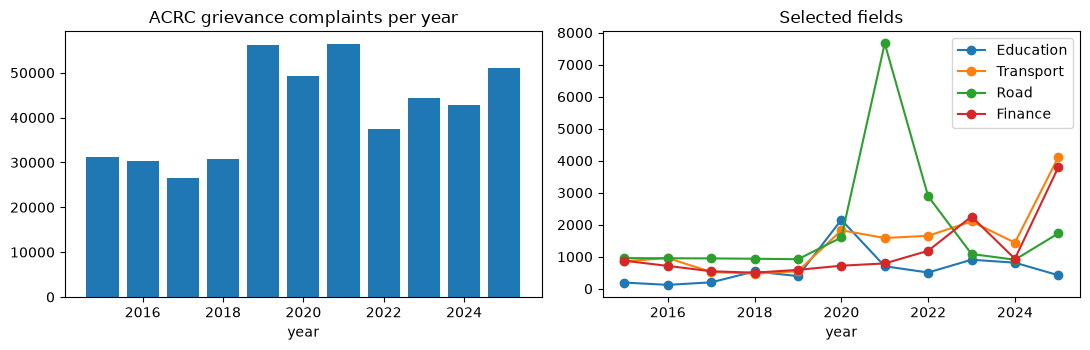

In [ ]:
import matplotlib.pyplot as plt
total = raw.groupBy("year").agg(F.sum("n").alias("n")).orderBy("year").toPandas()
top = raw.where(F.col("field").isin("재정", "교통", "도로", "교육")).toPandas().pivot(index="year", columns="field", values="n")
top.columns = ["Education" if c == "교육" else "Road" if c == "도로" else "Finance" if c == "재정" else "Transport" for c in top.columns]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(total["year"], total["n"]); ax[0].set_title("ACRC grievance complaints per year"); ax[0].set_xlabel("year")
top.plot(ax=ax[1], marker="o"); ax[1].set_title("Selected fields"); ax[1].set_xlabel("year")
plt.tight_layout(); plt.show()

## 6단계 · [레이크 · Spark] 발언 정제 · 집계 — 그리고 두 데이터 엮기

bronze 발언을 silver 로 정제합니다. 「네.」 「예, 그렇습니다.」 같은 짧은 발언(40자 미만)은 검색 근거로 쓸 수 없어 빼고, 4단계 Tip 의 중복도 걷어 냅니다.

In [ ]:
bronze = spark.read.parquet(BRONZE)
silver = (bronze.dropDuplicates(["confer_num", "seq"])
                .where(F.length("text") >= 40)
                .drop("ingested_at"))
silver.write.mode("overwrite").parquet(os.path.join(LAKE, "silver/speeches"))

comm_stats = (silver.groupBy("comm")
              .agg(F.count("*").alias("speeches"),
                   F.countDistinct("speaker").alias("speakers"),
                   F.round(F.avg(F.length("text"))).alias("avg_len"))
              .orderBy(F.desc("speeches")))
print("silver 발언:", silver.count())
comm_stats.show()

silver 발언: 1321


+--------------+--------+--------+-------+
|          comm|speeches|speakers|avg_len|
+--------------+--------+--------+-------+
|    정무위원회|     647|      25|  222.0|
|국토교통위원회|     254|      29|  271.0|
|    교육위원회|     213|      18|  215.0|
|    국방위원회|     140|      16|  267.0|
|기획재정위원회|      67|      11|  322.0|
+--------------+--------+--------+-------+



> **확인 포인트** — 40자 이상 발언 **1,321건**(bronze 2,788건의 절반 가량이 짧은 발언이었습니다). 정무위원회 647건이 가장 많고, 기획재정위원회가 67건으로 가장 적습니다.

In [ ]:
cs = comm_stats.toPandas().set_index("comm")
assert silver.count() == 1321
assert (cs.loc["정무위원회", "speeches"], cs.loc["기획재정위원회", "speeches"]) == (647, 67)

이제 두 데이터를 엮습니다. 민원 「분야」와 회의록 「위원회」는 공통 열이 없으므로, 분야마다 **소관 상임위원회**를 적은 연결표를 직접 만들어야 합니다(10장 ERD 의 다대다 연결 테이블).
국회 상임위원회의 소관 부처를 기준으로 했습니다 — 재정은 기획재정부(기획재정위원회)와 금융위원회 · 공정거래위원회(정무위원회)에 걸칩니다. 권익위의 다른 통계 파일은 같은 분야를 「재정 · 금융 · 보험 · 공정거래」로 적습니다.

In [ ]:
FIELD_COMM = [("재정", "기획재정위원회"), ("재정", "정무위원회"), ("세무", "기획재정위원회"),
              ("교통", "국토교통위원회"), ("도로", "국토교통위원회"), ("주택", "국토교통위원회"), ("건축", "국토교통위원회"),
              ("국방", "국방위원회"), ("군사", "국방위원회"), ("보훈", "정무위원회"), ("교육", "교육위원회")]
link = spark.createDataFrame(FIELD_COMM, "field STRING, comm STRING")

gold = (growth.where(F.col("year") == 2025)
              .join(link, "field")
              .join(silver.groupBy("comm").agg(F.count("*").alias("speeches")), "comm", "left")
              .select("field", "prev", "n", "diff", "rate", "comm", "speeches")
              .orderBy(F.desc("diff"), "comm"))
gold.write.mode("overwrite").parquet(os.path.join(LAKE, "gold/field_policy"))
gold_pd = gold.toPandas()
gold_pd

,field,prev,n,diff,rate,comm,speeches
0,재정,936,3796,2860,305.6,기획재정위원회,67
1,재정,936,3796,2860,305.6,정무위원회,647
2,교통,1441,4112,2671,185.4,국토교통위원회,254
3,도로,908,1730,822,90.5,국토교통위원회,254
4,국방,556,865,309,55.6,국방위원회,140
5,세무,875,1050,175,20.0,기획재정위원회,67
6,주택,735,827,92,12.5,국토교통위원회,254
7,군사,26,85,59,226.9,국방위원회,140
8,보훈,376,393,17,4.5,정무위원회,647
9,건축,445,391,-54,-12.1,국토교통위원회,254


> **확인 포인트** — 재정 → 기획재정위원회(67건) · 정무위원회(647건), 교통 · 도로 → 국토교통위원회(254건), 국방 → 국방위원회(140건)로 연결됩니다. 표는 분야 × 위원회 한 줄씩이라 재정은 두 줄입니다.

In [ ]:
assert gold_pd.iloc[0]["field"] == "재정" and set(gold_pd[gold_pd["field"] == "재정"]["comm"]) == {"기획재정위원회", "정무위원회"}
assert int(gold_pd[(gold_pd["field"] == "교통")]["speeches"].iloc[0]) == 254

> **Aebon's Tip** — 연결표는 코드 안의 목록보다 **레이크의 작은 테이블**(`gold/field_comm`)로 두는 편이 낫습니다. 위원회 개편(예: 부처 이름이 바뀌어 위원회 이름이 바뀜)이 있을 때 코드 대신 표만 고치면 되고, 언제 바꿨는지도 남습니다.

## 7단계 · [RAG] 발언 청킹 · 임베딩 · Qdrant

발언 하나를 청크 하나로 삼되, 400자가 넘는 긴 발언은 **문장 경계**에서 나눕니다(7주차 7-2장). 조각마다 위원회 · 날짜 · 발언자 · 직위를 payload 로 붙입니다. 이 payload 가 답의 출처이자 8단계의 필터 조건이 됩니다.
임베딩할 글 앞에 `직위 이름:` 을 붙여 두면 「장관 답변」처럼 누가 말했는지도 검색에 반영됩니다.

In [ ]:
def split_sentences(text, limit=400):
    sents = re.split(r"(?<=[.?!])\s+|\n", text)
    out, buf = [], ""
    for s in (x.strip() for x in sents):
        if not s:
            continue
        if buf and len(buf) + len(s) + 1 > limit:
            out.append(buf)
            buf = s
        else:
            buf = (buf + " " + s).strip()
    if buf:
        out.append(buf)
    return out

sv = silver.orderBy("confer_num", "seq").toPandas()
chunks = []
for r in sv.itertuples():
    for k, piece in enumerate(split_sentences(r.text)):
        chunks.append({"comm": r.comm, "date": r.date, "confer_num": int(r.confer_num), "seq": int(r.seq),
                       "speaker": r.speaker, "position": r.position, "part": k, "text": piece})
print(len(chunks), "조각")

1696 조각


In [ ]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
from sentence_transformers import SentenceTransformer
from qdrant_client import QdrantClient, models

model = SentenceTransformer("jhgan/ko-sroberta-multitask")
qd = QdrantClient(":memory:")
vecs = model.encode([f"{c['position']} {c['speaker']}: {c['text']}" for c in chunks], batch_size=64, normalize_embeddings=True)
qd.create_collection("speeches", vectors_config=models.VectorParams(size=768, distance=models.Distance.COSINE))
qd.upsert("speeches", [models.PointStruct(id=i, vector=v.tolist(), payload=c) for i, (v, c) in enumerate(zip(vecs, chunks))])
print(qd.count("speeches").count)

1696


> **확인 포인트** — 조각 **1,696개**가 모두 들어갑니다(Colab CPU 에서 1분 안팎).

In [ ]:
assert len(chunks) == 1696 and qd.count("speeches").count == 1696

## 8단계 · [RAG] 민원이 늘어난 분야 → 관련 정책 발언 검색

gold 표에서 늘어난 분야 위 4개를 골라, 분야마다 **질문 문장**과 **소관 위원회 필터**로 검색합니다. 질문 문장은 그 분야 민원에 흔한 주제로 직접 정합니다(이 노트북의 문장은 예시입니다).

In [ ]:
FIELD_QUERY = {
    "재정": "세금 감면과 세제 지원 확대",
    "교통": "개인형 이동장치 전동킥보드 안전 관리",
    "도로": "도로 공사 현장의 안전사고",
    "국방": "군 간부 처우 개선",
}

def search(q, comms=None, k=3):
    flt = None
    if comms:
        flt = models.Filter(must=[models.FieldCondition(key="comm", match=models.MatchAny(any=comms))])
    qv = model.encode(q, normalize_embeddings=True).tolist()
    return qd.query_points("speeches", query=qv, query_filter=flt, limit=k).points

top_fields = g25["field"].head(4).tolist()
rows = []
for field in top_fields:
    comms = sorted(gold_pd[gold_pd["field"] == field]["comm"].tolist())
    hit = search(FIELD_QUERY[field], comms)[0]
    p = hit.payload
    rows.append({"field": field, "diff": int(g25.set_index("field").loc[field, "diff"]), "comm": p["comm"], "date": p["date"],
                 "who": f"{p['position']} {p['speaker']}", "score": round(hit.score, 3), "text": p["text"][:80]})
report = pd.DataFrame(rows)
report

,field,diff,comm,date,who,score,text
0,재정,2860,기획재정위원회,2025-11-30,소위원장 박수영,0.684,또 장애인 표준사업장에 대한 세액감면 제도의 적용기한을 2028년까지 3년 연장하는...
1,교통,2671,국토교통위원회,2025-12-17,소위원장 복기왕,0.527,대안의 주요 내용은 제명을 도로교통법과의 정합성 등을 고려하여 ‘개인형 이동장치의 ...
2,도로,822,국토교통위원회,2025-12-17,위원 정준호,0.631,내용을 잠깐 한번 보겠습니다. 보고서를 보니까 사고 경위에 대해서 광주대표도서관 신...
3,국방,309,국방위원회,2025-11-27,국방부장관직무대리 이두희,0.632,"예, 짧게 답변드리겠습니다. 군 간부의 처우 개선을 위해서 큰 관심을 가지시고 이렇..."


> **확인 포인트** — 네 분야의 1위 발언은 다음과 같습니다.
> 재정 → 2025-11-30 기획재정위원회 소위원장 박수영(장애인 표준사업장 세액감면 연장, 0.684) ·
> 교통 → 2025-12-17 국토교통위원회 소위원장 복기왕(개인형 이동장치 대여사업 등록제 · 최고 속도 20km, 0.527) ·
> 도로 → 2025-12-17 국토교통위원회 위원 정준호(공사 현장 사고 경위 질의, 0.631) ·
> 국방 → 2025-11-27 국방위원회 국방부장관직무대리 이두희(군 간부 처우 개선 답변, 0.632).

In [ ]:
assert report["comm"].tolist() == ["기획재정위원회", "국토교통위원회", "국토교통위원회", "국방위원회"]
assert report["who"].tolist() == ["소위원장 박수영", "소위원장 복기왕", "위원 정준호", "국방부장관직무대리 이두희"]
assert report["date"].tolist() == ["2025-11-30", "2025-12-17", "2025-12-17", "2025-11-27"]

**대조 — 위원회 필터를 빼면.** 먼저 위의 네 질문을 필터 없이 던져, 위 5개 중 소관 위원회 발언이 몇 개인지 셉니다.

In [ ]:
mix = []
for field in top_fields:
    comms = sorted(gold_pd[gold_pd["field"] == field]["comm"].tolist())
    for rank, h in enumerate(search(FIELD_QUERY[field], None, k=5), 1):
        mix.append({"field": field, "rank": rank, "comm": h.payload["comm"], "in_scope": h.payload["comm"] in comms})
mix = pd.DataFrame(mix)
print(mix.groupby("field", sort=False)["in_scope"].sum().rename("in_scope_of_top5"))
mix[~mix["in_scope"]]

field
재정    4
교통    5
도로    4
국방    5
Name: in_scope_of_top5, dtype: int64


,field,rank,comm,in_scope
3,재정,4,국토교통위원회,False
13,도로,4,정무위원회,False


> **확인 포인트** — 20개 중 **18개**가 이미 소관 위원회 발언입니다. 질문이 구체적이면(전동킥보드 · 세액감면) 필터 없이도 대체로 맞습니다.

In [ ]:
assert mix["in_scope"].sum() == 18

그런데 실제 사용자는 「예산을 늘려 처우를 개선해야 한다는 이야기」처럼 **어느 분야에나 나올 법한 질문**을 던집니다. 국방 분야에서 이 질문을 필터 없이 · 있게 던져 봅니다.

In [ ]:
generic = "예산을 늘려 처우를 개선해야 합니다"
free = search(generic, None, k=5)
scoped = search(generic, ["국방위원회"], k=5)
print("필터 없음:", [h.payload["comm"] for h in free])
print("국방위원회:", scoped[0].payload["date"], scoped[0].payload["position"], scoped[0].payload["speaker"], scoped[0].payload["text"][:60])

필터 없음: ['교육위원회', '교육위원회', '기획재정위원회', '교육위원회', '정무위원회']
국방위원회: 2025-11-27 의원 박선원 그래서 우리 현실에 맞는 특별법을 마련했습니다. 법안 마련 과정에서는 실제 이전 사업을 추진 중인 지방자치단


> **확인 포인트** — 필터가 없으면 위 5개가 교육위원회 3개 · 기획재정위원회 · 정무위원회로, **국방위원회 발언이 하나도 없습니다.** 필터를 걸어야 국방위원회 발언(2025-11-27 의원 박선원)이 1위로 나옵니다.
> 질문 문장만으로는 「어느 분야의 이야기인가」를 모델이 알 수 없으므로, 6단계에서 만든 분야 ↔ 위원회 연결이 검색 조건으로 들어가야 두 데이터가 실제로 엮입니다.

In [ ]:
assert free[0].payload["comm"] == "교육위원회" and "국방위원회" not in [h.payload["comm"] for h in free]
assert scoped[0].payload["comm"] == "국방위원회"

> **Aebon's Tip** — 필터는 검색 결과를 「맞는 위원회 안에서」로 묶어 줄 뿐, 그 발언이 정말 민원과 같은 주제인지는 보장하지 않습니다. 점수(0.4~0.6대)를 함께 보여 주고, 질문 세트 20개쯤에 대해 사람이 맞다 / 아니다를 표시해 정답률을 재는 것이 RAG 담당의 다음 일입니다.

## 9단계 · [서비스] 요약 답변(키가 있으면) · Streamlit 화면

검색한 발언 3개를 근거로 「이 분야에 대해 국회에서 어떤 논의가 있었는지」를 gpt-4o-mini 로 요약합니다. 키가 없으면 근거 발언을 그대로 보여 줍니다(Colab 이면 왼쪽 열쇠 아이콘 「보안 비밀」에 `OPENAI_API_KEY`).

In [ ]:
KEY = os.environ.get("OPENAI_API_KEY")
if not KEY:
    try:
        from google.colab import userdata
        KEY = userdata.get("OPENAI_API_KEY")
    except Exception:
        KEY = None

field = top_fields[1]
comms = sorted(gold_pd[gold_pd["field"] == field]["comm"].tolist())
hits = search(FIELD_QUERY[field], comms)
ctx = "\n\n".join(f"[{h.payload['date']} {h.payload['comm']} {h.payload['position']} {h.payload['speaker']}] {h.payload['text']}" for h in hits)
prompt = (f"국민권익위원회 고충민원 중 '{field}' 분야가 2025년에 전년보다 크게 늘었습니다.\n"
          f"다음은 소관 상임위원회 회의록 발언입니다.\n\n{ctx}\n\n"
          "발언 내용만 근거로, 이 분야에 대해 어떤 정책 논의가 있었는지 3문장으로 요약해줘. "
          "문장마다 [날짜 발언자] 형식으로 근거를 붙이고, 발언에 없는 내용은 쓰지 말아줘.")

if KEY:
    need("openai")
    from openai import OpenAI
    res = OpenAI(api_key=KEY).chat.completions.create(model="gpt-4o-mini", temperature=0,
                                                      messages=[{"role": "user", "content": prompt}])
    print(res.choices[0].message.content)
else:
    print("OpenAI 키가 없어 요약은 건너뜁니다. 근거 발언:\n")
    print(ctx)

OpenAI 키가 없어 요약은 건너뜁니다. 근거 발언:

[2025-12-17 국토교통위원회 소위원장 복기왕] 대안의 주요 내용은 제명을 도로교통법과의 정합성 등을 고려하여 ‘개인형 이동장치의 안전 및 관리에 관한 법률’로 하고 현재 자유업으로 운영되고 있는 개인형 이동장치 대여사업을 등록제로 전환하여 체계적으로 관리하며 개인형 이동장치의 안전한 이용을 위해 대여용 개인형 이동장치의 최고 속도를 시속 25㎞에서 20㎞로 하향하고 개인형 이동장치를 임차하는 이용자는 교통안전교육을 의무적으로 받도록 함으로써 개인형 이동장치의 안전한 이용과 체계적 관리를 위한 제도적 기반을 마련하려는 것입니다.

[2025-09-25 국토교통위원회 소위원장 복기왕] 대안의 주요 내용은 공해상에서 국제민간항공협약 및 같은 협약 부속서의 준수 의무를 명시하고 항공교통업무의 표준화·인력수급·교육훈련 등 항공교통서비스제공 업무 수행에 관한 법적 근거를 마련하며, 재난·재해의 예방 및 대응활동 시 국가 등이 운영하는 무인비행장치에 관련 특례가 적용될 수 있도록 하는 한편 누구든지 비행금지구역에서 항공교통의 안전을 저해할 수 있는 무인자유기구를 외부에 매단 물건의 무게와 관계없이 비행시키려는 것을 금지하고 위반 시 처벌규정을 신설하려는 것입니다. 보다 자세한 내용은 배부해 드린 유인물을 참조해 주시고 우리 소위원회에서 심사보고한 내용대로 의결해 주시기 바랍니다. 감사합니다.

[2025-09-25 국토교통위원회 국토교통부교통물류실장 엄정희] 사실 이게 이번에 제도개선을 했던 취지가 일단 기계식주차장이 효율성도 높을 뿐더러 지금 24년 8월에 기계식주차장 안전관리 강화안을 발표했습니다. 그래서 안전 문제에는 저촉이 없을 것이라 판단을 했기 때문에 이런……


화면은 Streamlit(8주차)으로 만듭니다. 노트북에서는 파일만 만들어 두고, 실행은 내 컴퓨터에서 `streamlit run app.py` 로 합니다. 10단계에서 만드는 `t2_tasks.py` 의 함수를 그대로 불러 씁니다.

In [ ]:
%%writefile app.py
import pandas as pd
import streamlit as st
import t2_tasks as T

st.set_page_config(page_title="정책 · 민원 인텔리전스", layout="wide")
st.title("민원이 늘어난 분야 → 관련 국회 발언")

gold = pd.read_parquet(f"{T.LAKE}/gold/field_policy")
st.subheader("2025년 고충민원 증감(전년 대비)")
st.dataframe(gold, use_container_width=True)

field = st.selectbox("분야", gold.sort_values("diff", ascending=False)["field"].unique())
q = st.text_input("질문", T.FIELD_QUERY.get(field, field))
if q:
    comms = sorted(gold[gold["field"] == field]["comm"].dropna().unique())
    for h in T.search(q, comms, k=5):
        p = h.payload
        with st.container(border=True):
            st.caption(f"{p['date']} · {p['comm']} · {p['position']} {p['speaker']} · 유사도 {h.score:.3f}")
            st.write(p["text"])

Writing app.py


## 10단계 · [오케스트레이션] 태스크로 나누고 Airflow DAG 로 묶기

지금까지의 단계를 **태스크 다섯 개**로 나눕니다. 태스크는 서로 다른 프로세스에서 돌 수 있으므로, 태스크 사이에서 넘겨야 하는 것은 **파일(레이크)** 로 남겨야 합니다 — 메모리의 DataFrame 이나 `:memory:` Qdrant 는 다음 태스크로 넘어가지 않습니다. 그래서 색인은 폴더에 저장하는 Qdrant(`path=`)로 바꿉니다.

| 태스크 | 읽는 것 | 남기는 것 |
| --- | --- | --- |
| collect_complaints | 공공데이터포털(또는 스냅샷) | raw/complaints |
| collect_minutes | 회의록 API · 원문(또는 스냅샷) | landing/minutes |
| stream_minutes | landing | bronze/minutes |
| build_gold | raw · bronze | silver · gold |
| build_index_and_report | silver · gold | qdrant/ · gold/report.csv |

In [ ]:
%%writefile t2_tasks.py
"""T2 정책 · 민원 인텔리전스 — Airflow 태스크가 부르는 함수들(노트북 2~8단계를 묶은 것)."""
import os, json, gzip, re, shutil
import pandas as pd

LAKE = os.environ.get("T2_LAKE", "lake_dag")
DATA = os.environ.get("T2_DATA", "data")
SCHEMA = "confer_num LONG, title STRING, comm STRING, date STRING, seq LONG, speaker STRING, position STRING, text STRING"
FIELD_COMM = [("재정", "기획재정위원회"), ("재정", "정무위원회"), ("세무", "기획재정위원회"),
              ("교통", "국토교통위원회"), ("도로", "국토교통위원회"), ("주택", "국토교통위원회"), ("건축", "국토교통위원회"),
              ("국방", "국방위원회"), ("군사", "국방위원회"), ("보훈", "정무위원회"), ("교육", "교육위원회")]
FIELD_QUERY = {"재정": "세금 감면과 세제 지원 확대", "교통": "개인형 이동장치 전동킥보드 안전 관리",
               "도로": "도로 공사 현장의 안전사고", "국방": "군 간부 처우 개선"}
_model = None


def _spark():
    import sys
    from pyspark.sql import SparkSession
    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
    os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
    s = (SparkSession.builder.master("local[2]").appName("t2-dag")
         .config("spark.sql.shuffle.partitions", "4").config("spark.ui.enabled", "false").getOrCreate())
    s.sparkContext.setLogLevel("ERROR")
    return s


def _embed(texts):
    global _model
    from sentence_transformers import SentenceTransformer
    if _model is None:
        _model = SentenceTransformer("jhgan/ko-sroberta-multitask")
    return _model.encode(texts, batch_size=64, normalize_embeddings=True)


def collect_complaints():
    os.makedirs(f"{LAKE}/raw/complaints", exist_ok=True)
    shutil.copy(f"{DATA}/acrc_complaints_by_field_2015_2025.csv", f"{LAKE}/raw/complaints/")


def collect_minutes():
    os.makedirs(f"{LAKE}/landing/minutes", exist_ok=True)
    by = {}
    with gzip.open(f"{DATA}/assembly_minutes_2025h2.jsonl.gz", "rt", encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            by.setdefault(r["confer_num"], []).append(line)
    for cn, lines in by.items():
        with open(f"{LAKE}/landing/minutes/meeting_{cn}.jsonl", "w", encoding="utf-8") as f:
            f.writelines(lines)


def stream_minutes():
    from pyspark.sql import functions as F
    s = _spark()
    q = (s.readStream.schema(SCHEMA).json(f"{LAKE}/landing/minutes").withColumn("ingested_at", F.current_timestamp())
         .writeStream.format("parquet").option("checkpointLocation", f"{LAKE}/_checkpoints/minutes")
         .trigger(availableNow=True).start(f"{LAKE}/bronze/minutes"))
    q.awaitTermination()


def build_gold():
    from pyspark.sql import functions as F, Window
    s = _spark()
    raw = (s.read.option("header", True).option("encoding", "cp949").csv(f"{LAKE}/raw/complaints")
           .select(F.col("기준연도").cast("int").alias("year"), F.col("분야명").alias("field"), F.col("접수건수").cast("int").alias("n")))
    w = Window.partitionBy("field").orderBy("year")
    growth = raw.withColumn("prev", F.lag("n").over(w)).withColumn("diff", F.col("n") - F.col("prev")) \
                .withColumn("rate", F.round(F.col("diff") / F.col("prev") * 100, 1))
    silver = (s.read.parquet(f"{LAKE}/bronze/minutes").dropDuplicates(["confer_num", "seq"])
              .where(F.length("text") >= 40).drop("ingested_at"))
    silver.write.mode("overwrite").parquet(f"{LAKE}/silver/speeches")
    link = s.createDataFrame(FIELD_COMM, "field STRING, comm STRING")
    gold = (growth.where(F.col("year") == 2025).join(link, "field")
            .join(silver.groupBy("comm").agg(F.count("*").alias("speeches")), "comm", "left")
            .select("field", "prev", "n", "diff", "rate", "comm", "speeches").orderBy(F.desc("diff"), "comm"))
    gold.write.mode("overwrite").parquet(f"{LAKE}/gold/field_policy")


def _split(text, limit=400):
    out, buf = [], ""
    for x in re.split(r"(?<=[.?!])\s+|\n", text):
        x = x.strip()
        if not x:
            continue
        if buf and len(buf) + len(x) + 1 > limit:
            out.append(buf)
            buf = x
        else:
            buf = (buf + " " + x).strip()
    return out + ([buf] if buf else [])


def _client():
    from qdrant_client import QdrantClient
    return QdrantClient(path=f"{LAKE}/qdrant")


def search(q, comms=None, k=3):
    from qdrant_client import models
    flt = models.Filter(must=[models.FieldCondition(key="comm", match=models.MatchAny(any=comms))]) if comms else None
    c = _client()
    try:
        return c.query_points("speeches", query=_embed([q])[0].tolist(), query_filter=flt, limit=k).points
    finally:
        c.close()


def build_index_and_report():
    from qdrant_client import models
    sv = pd.read_parquet(f"{LAKE}/silver/speeches").sort_values(["confer_num", "seq"])
    chunks = [{"comm": r.comm, "date": r.date, "confer_num": int(r.confer_num), "seq": int(r.seq), "speaker": r.speaker,
               "position": r.position, "part": k, "text": piece}
              for r in sv.itertuples() for k, piece in enumerate(_split(r.text))]
    vecs = _embed([f"{c['position']} {c['speaker']}: {c['text']}" for c in chunks])
    c = _client()
    if c.collection_exists("speeches"):
        c.delete_collection("speeches")
    c.create_collection("speeches", vectors_config=models.VectorParams(size=768, distance=models.Distance.COSINE))
    c.upsert("speeches", [models.PointStruct(id=i, vector=v.tolist(), payload=p) for i, (v, p) in enumerate(zip(vecs, chunks))])
    c.close()
    gold = pd.read_parquet(f"{LAKE}/gold/field_policy")
    rows = []
    for field in [f for f in gold.sort_values("diff", ascending=False)["field"].unique() if f in FIELD_QUERY]:
        comms = sorted(gold[gold["field"] == field]["comm"].dropna().unique())
        h = search(FIELD_QUERY[field], comms)[0]
        rows.append({"field": field, "comm": h.payload["comm"], "date": h.payload["date"],
                     "who": f"{h.payload['position']} {h.payload['speaker']}", "score": round(h.score, 3)})
    pd.DataFrame(rows).to_csv(f"{LAKE}/gold/report.csv", index=False)
    return len(chunks)

Writing t2_tasks.py


DAG 파일은 태스크의 **순서**와 **재시도**만 정의합니다. 무엇을 하는지는 모두 `t2_tasks.py` 에 있으므로, 노트북에서 같은 함수를 순서대로 부르면 DAG 를 한 번 돌린 것과 같습니다(8주차 8-2장 — PythonOperator · `>>` · retries).

In [ ]:
os.makedirs("dags", exist_ok=True)

In [ ]:
%%writefile dags/t2_policy_intel.py
from datetime import datetime, timedelta

from airflow import DAG
from airflow.operators.python import PythonOperator

import t2_tasks as T

default_args = {"retries": 2, "retry_delay": timedelta(minutes=3)}

with DAG(
    dag_id="t2_policy_intel",
    start_date=datetime(2026, 1, 1),
    schedule="@weekly",                 # 회의록은 매주 늘고, 민원 통계는 1년에 한 번 바뀐다
    catchup=False,
    default_args=default_args,
    tags=["data-eng", "T2"],
) as dag:
    complaints = PythonOperator(task_id="collect_complaints", python_callable=T.collect_complaints)
    minutes = PythonOperator(task_id="collect_minutes", python_callable=T.collect_minutes)
    stream = PythonOperator(task_id="stream_minutes", python_callable=T.stream_minutes)
    gold = PythonOperator(task_id="build_gold", python_callable=T.build_gold)
    index = PythonOperator(task_id="build_index_and_report", python_callable=T.build_index_and_report)

    minutes >> stream
    [complaints, stream] >> gold >> index

Writing dags/t2_policy_intel.py


일부러 순서를 어겨 봅니다. bronze 가 생기기 전에 `build_gold` 를 부르면 이렇게 실패합니다 — DAG 의 `>>` 가 막아 주는 일이 바로 이것입니다.

In [ ]:
import importlib
os.environ["T2_LAKE"] = "lake_dag"
shutil.rmtree("lake_dag", ignore_errors=True)
import t2_tasks as T
importlib.reload(T)

try:
    T.build_gold()
except Exception as e:
    print("build_gold 실패:", type(e).__name__, str(e).split("\n")[0][:90])

build_gold 실패: AnalysisException [PATH_NOT_FOUND] Path does not exist: file:…


이제 DAG 가 정한 순서대로 한 번 돌립니다.

In [ ]:
for task in [T.collect_complaints, T.collect_minutes, T.stream_minutes, T.build_gold, T.build_index_and_report]:
    out = task()
    print("완료:", task.__name__, "" if out is None else out)

dag_report = pd.read_csv("lake_dag/gold/report.csv")
dag_report

완료: collect_complaints 
완료: collect_minutes 


완료: stream_minutes 


완료: build_gold 


완료: build_index_and_report 1696


,field,comm,date,who,score
0,재정,기획재정위원회,2025-11-30,소위원장 박수영,0.684
1,교통,국토교통위원회,2025-12-17,소위원장 복기왕,0.527
2,도로,국토교통위원회,2025-12-17,위원 정준호,0.631
3,국방,국방위원회,2025-11-27,국방부장관직무대리 이두희,0.632


> **확인 포인트** — 다섯 태스크가 끝나면 `lake_dag/gold/report.csv` 의 분야 · 위원회 · 날짜 · 발언자가 8단계의 표와 똑같습니다.

In [ ]:
assert dag_report[["field", "comm", "date", "who"]].values.tolist() == report[["field", "comm", "date", "who"]].values.tolist()
assert os.path.exists("dags/t2_policy_intel.py") and os.path.exists("app.py")

> **Aebon's Tip** — 8주차 로컬 Airflow 로 옮길 때는 `dags/` 폴더에 `t2_policy_intel.py` 와 `t2_tasks.py` 를 함께 넣고, `T2_LAKE` · `T2_DATA` 환경 변수를 컨테이너 안의 경로(또는 MinIO 를 마운트한 경로)로 맞추세요. `collect_minutes` 를 스냅샷 대신 3단계의 `list_meetings` · `fetch_speeches` 로 바꾸면 매주 새 회의가 landing 에 쌓이고, `stream_minutes` 는 체크포인트 덕분에 새 회의만 처리합니다.

## 11단계 · 더 해 보기 · 발표 준비

- **수집 · 스트리밍**: 회의록 API 인증키를 받아 2025년 한 해 국토교통위원회 회의를 모두 받으세요. landing 대신 Kafka 토픽(`minutes.raw`)에 회의 단위 메시지를 넣고, Spark 가 `format("kafka")` 로 읽게 바꿔 보세요(6주차).
- **레이크 · Spark**: bronze · silver · gold 를 MinIO + Iceberg 테이블로 옮기고(19장), 분야 연결표를 Iceberg 테이블로 관리해 보세요. 연도별로 「늘어난 분야 위 3개」를 모두 구하면 몇 년 치 비교가 됩니다.
- **RAG · 서비스**: 분야마다 질문 5개씩 20개 질문 세트를 만들어, 필터가 있을 때 · 없을 때 1위가 맞는지 사람이 표시하고 정답률을 재세요. `streamlit run app.py` 로 화면을 띄워 다른 수강생에게 써 보게 하세요.
- **오케스트레이션**: 8주차 로컬 Airflow 에 DAG 를 올리고, `build_index_and_report` 가 실패했을 때 재시도 2회 뒤 알림이 가게 해 보세요. 매주 돌 때 이미 색인한 발언은 건너뛰도록(멱등) 고치는 것이 다음 과제입니다.
- 발표에서는 「민원 통계의 분류(기타가 절반)」 「분야 ↔ 위원회 연결표가 내 판단이라는 점」 「회의록 스냅샷이 8개 회의뿐이라는 점」을 한계로 함께 밝히세요.